# OTFS: modulation in delay–Doppler coordinates

OFDM (`lte_sim`) turns a multipath channel into a set of flat subcarriers, but only as long as the channel does not change within a symbol. On a train, an aircraft or a satellite, Doppler breaks subcarrier orthogonality (ICI), and channel estimates go stale faster than pilots refresh them. The channel $H(t,f)$ on the time–frequency (TF) grid changes **everywhere**.

Yet there are few physical paths, and each is a **fixed** point: a delay $\tau_i$ (path length) and a Doppler $\nu_i$ (speed and angle). As a spreading function,
$$r(t)=\sum_i h_i\,e^{j2\pi\nu_i t}\,s(t-\tau_i)\qquad\Longleftrightarrow\qquad h(\tau,\nu)=\sum_i h_i\,\delta(\tau-\tau_i)\,\delta(\nu-\nu_i)$$
the channel is sparse and constant over tens of milliseconds. **OTFS** (Hadani et al., 2017) places symbols directly on a **delay–Doppler** (DD) grid $M\times N$ with spacing $\Delta\tau=1/(M\Delta f)$, $\Delta\nu=1/(NT)$. The move to TF is the **ISFFT**:
$$X[m,n]=\frac1{\sqrt{MN}}\sum_{k=0}^{N-1}\sum_{l=0}^{M-1}x[l,k]\,e^{\,j2\pi\left(\frac{nk}{N}-\frac{ml}{M}\right)},$$
followed by an ordinary OFDM modulator. The receiver does OFDM demodulation and an SFFT back. In DD the channel is a **two-dimensional circular convolution**:
$$y[l,k]\approx\sum_i h_i\,x\big[(l-l_i)_M,\,(k-k_i)_N\big]\,e^{j\phi_i(l,k)}.$$
Every DD symbol is spread over the **whole** $M\times N$ TF frame, so it sees all the fades at once and collects all of the time and frequency diversity. The channel, meanwhile, is a handful of numbers that stay fixed over the frame.

This and the following notebooks cover a family of "waveforms for Doppler channels": OTFS (here), **Zak-OTFS** (OTFS 2.0, the Zak lattice and fractional Doppler), **AFDM** and **OCDM** (chirps, relatives of LoRa) and **OTSM/ODDM** (a single carrier in DD).

1. The channel in TF and DD · 2. One DD symbol: pulses in time and a comb in frequency · 3. DD input–output and fractional Doppler · 4. OFDM vs OTFS at 500 km/h · 5. Embedded pilot and channel estimation · 6. The message-passing detector · 7. Peak-to-average power

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
M, N = 64, 16          # delay bins (subcarriers) × Doppler bins (OFDM symbols)
DF = 15e3              # subcarrier spacing, Hz
L_CP = 8               # CP in samples: one per frame for OTFS, one per symbol for OFDM
FC_GHZ = 4.0
SPEED_KMH = 500        # high-speed train
P_PATHS = 5            # paths; delays 0…P−1 samples, exponentially decaying power
FRAMES = 40            # channel realizations per BER point

rng = np.random.default_rng(SEED)

## Primitives: OTFS and OFDM modulators, a path-based channel, the effective matrix, LMMSE

In [2]:
MN = M * N
FS = M * DF; T = 1 / DF                       # sample 1/(MΔf), symbol T = 1/Δf
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
K_MAX = NU_MAX * N * T                        # maximum Doppler in bins of 1/(NT)
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)   # index = 2·b_Q + b_I (Gray)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, rng):
    b = rng.integers(0, 2, (B, MN, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

# ---------- modulators: a length-MN vector, index l·N + k (OTFS) or m·N + n (OFDM) ----------
def otfs_mod(x):
    """x[l,k] (…, M·N) → frame: an IDFT over Doppler gives N blocks of M samples, block n = column n; one CP for the whole frame."""
    X = x.reshape(x.shape[:-1] + (M, N))
    s = (np.fft.ifft(X, axis=-1) * np.sqrt(N)).swapaxes(-1, -2).reshape(x.shape[:-1] + (MN,))
    return np.concatenate([s[..., -L_CP:], s], -1)

def otfs_demod(r):
    Y = r[..., L_CP:L_CP + MN].reshape(r.shape[:-1] + (N, M)).swapaxes(-1, -2)
    return (np.fft.fft(Y, axis=-1) / np.sqrt(N)).reshape(r.shape[:-1] + (MN,))

def isfft(x):
    """ISFFT: x[l,k] → X[m,n] = (1/√MN) Σ x[l,k]·e^{j2π(nk/N − ml/M)}"""
    X = x.reshape(x.shape[:-1] + (M, N))
    return np.fft.ifft(np.fft.fft(X, axis=-2), axis=-1) * np.sqrt(N / M)

def ofdm_mod(X, cp=L_CP):
    """X[m,n] (…, M·N) → N OFDM symbols, each with its own CP"""
    G = X.reshape(X.shape[:-1] + (M, N))
    s = (np.fft.ifft(G, axis=-2) * np.sqrt(M)).swapaxes(-1, -2)     # (…, N, M)
    return np.concatenate([s[..., -cp:], s], -1).reshape(X.shape[:-1] + (N * (M + cp),))

def ofdm_demod(r, cp=L_CP):
    s = r.reshape(r.shape[:-1] + (N, M + cp))[..., cp:]
    return (np.fft.fft(s, axis=-1) / np.sqrt(M)).swapaxes(-1, -2).reshape(r.shape[:-1] + (MN,))

# ---------- doubly dispersive channel: paths (h_i, delay l_i, Doppler ν_i) ----------
def draw_paths(rng, integer=False):
    """P paths at delays 0…P−1, Doppler ν_max·cos θ (Jakes); integer=True rounds the Doppler to a 1/(NT) bin."""
    p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
    nu = NU_MAX * np.cos(rng.uniform(0, 2 * np.pi, P_PATHS))
    if integer:
        nu = np.round(nu * N * T) / (N * T)
    return [(np.sqrt(pi) * crandn((), rng), l, v) for l, (pi, v) in enumerate(zip(p, nu))]

def channel(s, paths):
    """r[n] = Σ_i h_i·e^{j2πν_i n/f_s}·s[n − l_i]"""
    n = np.arange(s.shape[-1]); r = np.zeros(s.shape, complex)
    for h, l, nu in paths:
        r[..., l:] += h * np.exp(2j * np.pi * nu * n[l:] / FS) * s[..., :s.shape[-1] - l]
    return r

def eff_matrix(paths, mod=otfs_mod, demod=otfs_demod):
    """Effective MN×MN matrix "symbols → demodulator output": every basis vector is passed through the chain."""
    return demod(channel(mod(np.eye(MN, dtype=complex)), paths)).T

def lmmse(H, y, n0):
    """x̂ = (HᴴH + N0·I)⁻¹Hᴴy for a batch y (B, MN)"""
    return np.linalg.solve(H.conj().T @ H + n0 * np.eye(H.shape[1]), H.conj().T @ y.T).T

def tf_channel(paths):
    """H(t, f) on the grid: symbol midpoints × subcarriers"""
    t = (np.arange(N) * (M + L_CP) + L_CP + M / 2) / FS; f = np.arange(M) * DF
    return sum(h * np.exp(2j * np.pi * nu * t)[None, :] * np.exp(-2j * np.pi * f * l / FS)[:, None] for h, l, nu in paths)

# self-checks
_b, _x = qpsk_bits(3, rng)
assert np.allclose(otfs_demod(otfs_mod(_x)), _x) and np.allclose(ofdm_demod(ofdm_mod(_x)), _x)
_s_isfft = (np.fft.ifft(isfft(_x), axis=-2) * np.sqrt(M)).swapaxes(-1, -2).reshape(3, MN)    # ISFFT → OFDM without CP
assert np.allclose(_s_isfft, otfs_mod(_x)[:, L_CP:]), "ISFFT + Heisenberg ≠ IDFT по доплеру"
print(f"Grid {M}×{N}: Δτ = 1/(MΔf) = {1e6/FS:.2f} µs, Δν = 1/(NT) = {1/(N*T):.1f} Hz; frame {MN/FS*1e3:.3f} ms + CP {L_CP} samples")
print(f"{SPEED_KMH} km/h at {FC_GHZ} GHz: ν_max = {NU_MAX:.0f} Hz = {K_MAX:.2f} Doppler bins = {NU_MAX/DF:.3f}·Δf")
print(f"CP overhead: OTFS {L_CP/(MN+L_CP):.1%}, OFDM {L_CP/(M+L_CP):.1%}")

Grid 64×16: Δτ = 1/(MΔf) = 1.04 µs, Δν = 1/(NT) = 937.5 Hz; frame 1.067 ms + CP 8 samples
500 km/h at 4.0 GHz: ν_max = 1852 Hz = 1.98 Doppler bins = 0.123·Δf
CP overhead: OTFS 0.8%, OFDM 11.1%


## 1. One channel in TF and in DD
The model: $P$ paths at delays $0\dots P-1$ samples with an exponential profile, each with Doppler $\nu_i=\nu_\max\cos\theta_i$ (uniform angles of arrival, as in Jakes). At 500 km/h and 4 GHz $\nu_\max\approx1.85$ kHz, about 2 Doppler bins of $1/(NT)$.

Left: $|H(t,f)|$ over one 1.2 ms frame. The fades move both in frequency (delays) and in time (Doppler), and the coherence time $\approx0.42/\nu_\max$ is ~5× shorter than the frame. Middle: the same channel in DD, five points that do not move during the frame. Right: what one OFDM subcarrier sees: its coefficient goes through a fade several times per frame.

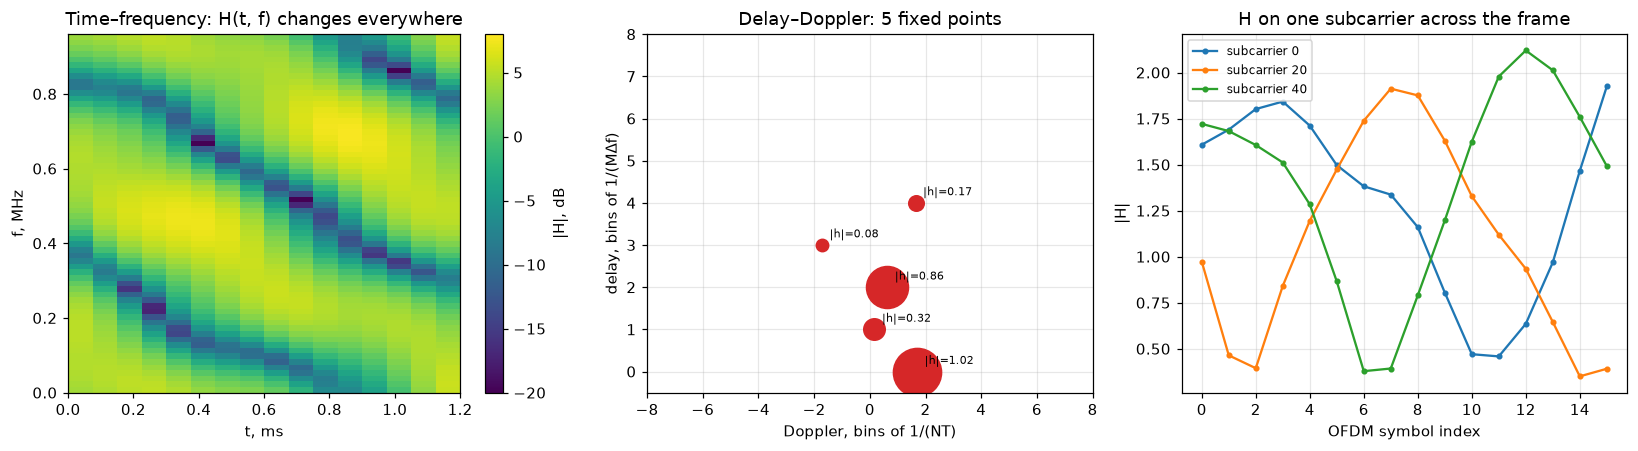

Coherence time 0.423/ν_max = 0.23 ms for a 1.20 ms frame: the TF channel decorrelates ~5 times per frame
In TF: 1024 complex numbers that change over time; in DD: 5 paths × (h, τ, ν) = 15 parameters, constant over the frame


In [3]:
pth = draw_paths(np.random.default_rng(3))
Htf = tf_channel(pth)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})
im = ax[0].imshow(20 * np.log10(np.abs(Htf)), origin="lower", aspect="auto", cmap="viridis",
                  extent=[0, N * (M + L_CP) / FS * 1e3, 0, M * DF / 1e6], vmin=-20, vmax=8)
plt.colorbar(im, ax=ax[0], label="|H|, dB"); ax[0].grid(False)
ax[0].set_xlabel("t, ms"); ax[0].set_ylabel("f, MHz"); ax[0].set_title("Time–frequency: H(t, f) changes everywhere")
for h, l, nu in pth:
    ax[1].plot(nu / (1 / (N * T)), l, "o", ms=6 + 25 * abs(h), color="C3")
    ax[1].annotate(f"|h|={abs(h):.2f}", (nu / (1 / (N * T)), l), xytext=(5, 5), textcoords="offset points", fontsize=7)
ax[1].set_xlim(-N / 2, N / 2); ax[1].set_ylim(-0.5, M / 8)
ax[1].set_xticks(np.arange(-N // 2, N // 2 + 1, 2)); ax[1].set_yticks(range(M // 8 + 1))
ax[1].set_xlabel("Doppler, bins of 1/(NT)"); ax[1].set_ylabel("delay, bins of 1/(MΔf)")
ax[1].set_title(f"Delay–Doppler: {P_PATHS} fixed points")
for m in (0, 20, 40):
    ax[2].plot(np.arange(N), np.abs(Htf[m]), "o-", ms=3, label=f"subcarrier {m}")
ax[2].set_xlabel("OFDM symbol index"); ax[2].set_ylabel("|H|"); ax[2].legend(fontsize=8)
ax[2].set_title("H on one subcarrier across the frame")
plt.tight_layout(); plt.show()
tc = 0.423 / NU_MAX
print(f"Coherence time 0.423/ν_max = {tc*1e3:.2f} ms for a {N*(M+L_CP)/FS*1e3:.2f} ms frame: the TF channel decorrelates ~{N*(M+L_CP)/FS/tc:.0f} times per frame")
print(f"In TF: {MN} complex numbers that change over time; in DD: {P_PATHS} paths × (h, τ, ν) = {3*P_PATHS} parameters, constant over the frame")

## 2. One DD symbol: N pulses in time
With a rectangular pulse, the ISFFT plus OFDM without CP collapse into a single IDFT along the Doppler axis:
$$s[l+nM]=\frac1{\sqrt N}\sum_{k}x[l,k]\,e^{\,j2\pi nk/N},\qquad n=0\dots N-1.$$
Symbol $(l_0,k_0)$ is $N$ pulses at positions $l_0+nM$ whose phase rotates by $2\pi k_0/N$ from pulse to pulse. Delay is **where** within the block, Doppler is **how fast** the phase rotates. In TF (left) the same symbol is a 2-D exponential of constant amplitude $1/\sqrt{MN}$ over the whole grid, and in the spectrum (right) it is a comb across the whole band. That is where the diversity comes from: the symbol is present at every frequency and at every moment of the frame.

There is a single CP for the whole frame: the convolution with the channel is circular over the frame, not per symbol. The overhead is 0.8 % instead of 11 % for OFDM with the same CP.

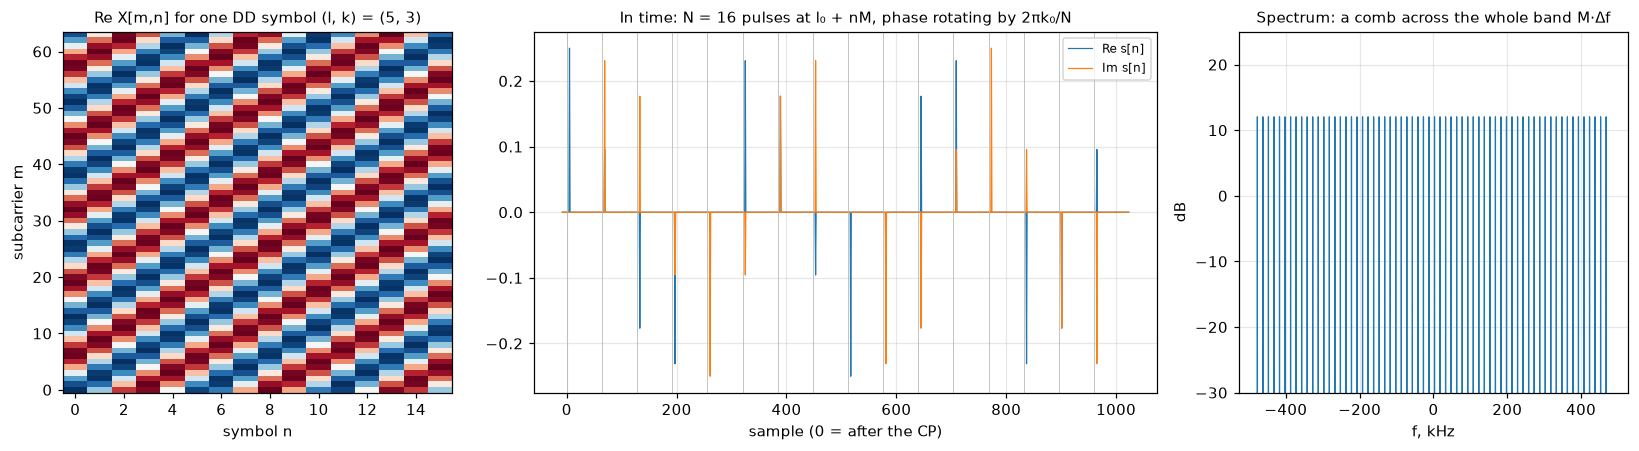

Pulse phase steps: [67.5 67.5 67.5 67.5 67.5]… °, theory 360·k₀/N = 67.5°
|X[m,n]| = 0.0312…0.0313 = 1/√MN = 0.0312: every DD symbol occupies the whole TF frame


In [4]:
l0, k0 = 5, 3
x = np.zeros(MN, complex); x[l0 * N + k0] = 1
X = isfft(x).reshape(M, N); s = otfs_mod(x)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.6, 1]})
ax[0].imshow(X.real, origin="lower", aspect="auto", cmap="RdBu", extent=[-0.5, N - 0.5, -0.5, M - 0.5])
ax[0].set_xlabel("symbol n"); ax[0].set_ylabel("subcarrier m"); ax[0].grid(False)
ax[0].set_title(f"Re X[m,n] for one DD symbol (l, k) = ({l0}, {k0})", fontsize=10)
n = np.arange(len(s)) - L_CP
ax[1].plot(n, s.real, "C0", lw=0.8, label="Re s[n]"); ax[1].plot(n, s.imag, "C1", lw=0.8, label="Im s[n]")
for b in range(N):
    ax[1].axvline(b * M, color="0.7", lw=0.5)
ax[1].set_xlabel("sample (0 = after the CP)"); ax[1].legend(fontsize=8, loc="upper right")
ax[1].set_title(f"In time: N = {N} pulses at l₀ + nM, phase rotating by 2πk₀/N", fontsize=10)
S = np.fft.fftshift(np.fft.fft(s[L_CP:])); f = np.fft.fftshift(np.fft.fftfreq(MN, 1 / FS))
ax[2].plot(f / 1e3, 20 * np.log10(np.abs(S) + 1e-9), lw=0.8)
ax[2].set_ylim(-30, 25); ax[2].set_xlabel("f, kHz"); ax[2].set_ylabel("dB")
ax[2].set_title("Spectrum: a comb across the whole band M·Δf", fontsize=10)
plt.tight_layout(); plt.show()
ph = np.angle(s[L_CP + l0 + M * np.arange(N)] * np.conj(s[L_CP + l0]))
print(f"Pulse phase steps: {np.degrees(np.diff(np.unwrap(ph))).round(1)[:5]}… °, theory 360·k₀/N = {360*k0/N:.1f}°")
print(f"|X[m,n]| = {np.abs(X).min():.4f}…{np.abs(X).max():.4f} = 1/√MN = {1/np.sqrt(MN):.4f}: every DD symbol occupies the whole TF frame")

## 3. DD input–output: integer and fractional Doppler
Send one pilot at $(l_p,k_p)$. Path $(h_i,l_i,\nu_i)$ shifts it by $l_i$ in delay and by $k_i=\nu_iNT$ in Doppler. If $k_i$ is an integer, that is exactly one cell with $|y|=|h_i|$, and the DD channel matrix has $P$ nonzeros per row. Its columns are circular shifts of each other (up to phases), i.e. the channel is **shift-invariant**.

Real Doppler is fractional. The phase $e^{j2\pi\nu t}$ over a frame of length $NT$ is not a whole number of periods, and along the Doppler axis the response is smeared by the **Dirichlet kernel**
$$\Big|\frac{\sin\pi(k-k_i)}{N\sin(\pi(k-k_i)/N)}\Big|.$$
In the worst case (half a bin) ~19 % of the energy leaves the two nearest bins, and a row of the matrix is no longer sparse ($P\cdot N$ elements). This is the main practical weakness of "classic" OTFS. Zak-OTFS (the next notebook) addresses it with a different choice of pulse.

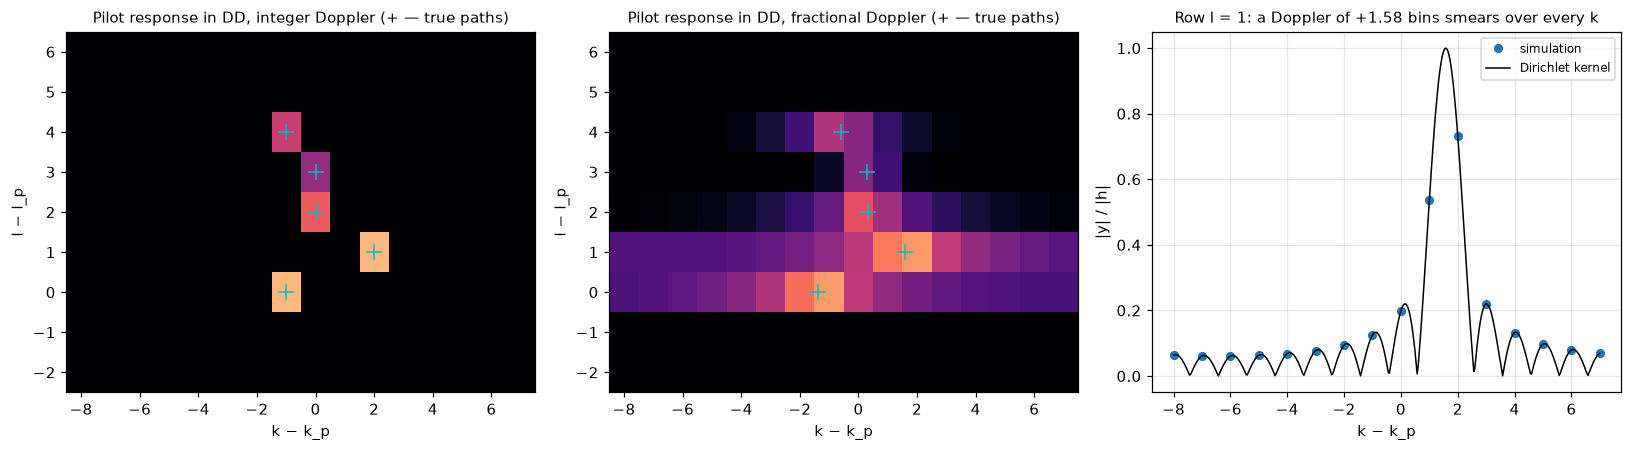

Integer Doppler: peak ↔ path
   l = 0, k = -1: |y| = 0.499, |h| = 0.499
   l = 1, k = +2: |y| = 0.514, |h| = 0.514
   l = 2, k = +0: |y| = 0.204, |h| = 0.204
   l = 3, k = +0: |y| = 0.069, |h| = 0.069
   l = 4, k = -1: |y| = 0.123, |h| = 0.123
Fractional Doppler: energy outside the 2 nearest bins — 17.7% for path l = 1 (fractional part 0.58), 18.7% in the worst case (0.5 bin)
Shift invariance: |H(·, p₂)| and shifted |H(·, p₁)| differ by at most 1.1e-16 (with one CP per frame OTFS is invariant up to phases)
Nonzeros per row of H_eff: integer Doppler 5.0 (= P = 5), fractional 80.0 (= P·N = 80)


In [5]:
def dirichlet(dk):
    """Doppler response to a fractional shift dk: magnitude of sin(π dk)/(N sin(π dk/N))"""
    dk = np.asarray(dk, float)
    with np.errstate(invalid="ignore", divide="ignore"):
        v = np.abs(np.sin(np.pi * dk) / (N * np.sin(np.pi * dk / N)))
    return np.where(np.abs(np.sin(np.pi * dk / N)) < 1e-12, 1.0, v)

lp, kp = M // 2, N // 2
SEED_S3 = 7   # a realization whose strongest path sits halfway between Doppler bins
xp = np.zeros(MN, complex); xp[lp * N + kp] = 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
res = {}
for a, integer, t in ((ax[0], True, "integer Doppler"), (ax[1], False, "fractional Doppler")):
    pth = draw_paths(np.random.default_rng(SEED_S3), integer)
    y = otfs_demod(channel(otfs_mod(xp), pth)).reshape(M, N)
    res[integer] = (pth, y)
    a.imshow(20 * np.log10(np.abs(y[lp - 2:lp + P_PATHS + 2]) + 1e-6), origin="lower", aspect="auto", cmap="magma", vmin=-40, vmax=0,
             extent=[-N / 2 - 0.5, N / 2 - 0.5, -2.5, P_PATHS + 1.5])
    for h, l, nu in pth:
        a.plot(nu * N * T, l, "c+", ms=10)
    a.set_xlabel("k − k_p"); a.set_ylabel("l − l_p"); a.set_title(f"Pilot response in DD, {t} (+ — true paths)", fontsize=10)
    a.grid(False)
pth, y = res[False]
hF, lF, nuF = max(pth, key=lambda p: abs(p[0]))
kk = np.arange(N) - kp
ax[2].plot(kk, np.abs(y[lp + lF]) / abs(hF), "C0o", ms=5, label="simulation")
kg = np.linspace(-N / 2, N / 2 - 1, 400)
ax[2].plot(kg, dirichlet(kg - nuF * N * T), "k-", lw=1, label="Dirichlet kernel")
ax[2].set_xlabel("k − k_p"); ax[2].set_ylabel("|y| / |h|"); ax[2].legend(fontsize=8)
ax[2].set_title(f"Row l = {lF}: a Doppler of {nuF*N*T:+.2f} bins smears over every k", fontsize=10)
plt.tight_layout(); plt.show()

pth_i, y_i = res[True]
print("Integer Doppler: peak ↔ path")
for h, l, nu in pth_i:
    k = int(round(nu * N * T))
    print(f"   l = {l}, k = {k:+d}: |y| = {abs(y_i[lp + l, (kp + k) % N]):.3f}, |h| = {abs(h):.3f}")
fr = nuF * N * T - np.floor(nuF * N * T)
out = lambda f_: 1 - np.sum(np.sort(dirichlet(np.arange(N) - N // 2 - f_))[-2:]**2)
print(f"Fractional Doppler: energy outside the 2 nearest bins — {out(fr):.1%} for path l = {lF} (fractional part {fr:.2f}), {out(0.5):.1%} in the worst case (0.5 bin)")
H = eff_matrix(pth_i)
c1, c2 = H[:, (lp * N + kp)], H[:, ((lp + 7) * N + kp + 3) % MN]
c1s = np.roll(c1.reshape(M, N), (7, 3), (0, 1)).ravel()
print(f"Shift invariance: |H(·, p₂)| and shifted |H(·, p₁)| differ by at most {np.max(np.abs(np.abs(c2) - np.abs(c1s))):.1e} (with one CP per frame OTFS is invariant up to phases)")
print(f"Nonzeros per row of H_eff: integer Doppler {np.mean(np.sum(np.abs(H) > 1e-6, 1)):.1f} (= P = {P_PATHS}), fractional {np.mean(np.sum(np.abs(eff_matrix(pth)) > 1e-6, 1)):.1f} (= P·N = {P_PATHS*N})")

## 4. OFDM vs OTFS at 500 km/h
**ICI in OFDM.** A subcarrier with Doppler $\nu$ over an interval $T$ no longer lands on its neighbours' nulls. The power that leaves the diagonal of the channel matrix is
$$P_\text{ICI}=1-\sum_ip_i\,\mathrm{sinc}^2(\nu_iT)\approx\frac{(\pi\nu_\max T)^2}{6}$$
(the same formula as in section 5 of `lte_sim`). At 500 km/h that is −16 dB, an SINR ceiling for a one-tap equalizer.

**Uncoded BER, QPSK**, a new channel every frame, perfect CSI:
- **OFDM, one tap** — division by the diagonal: it saturates on the ICI floor;
- **OFDM, full LMMSE** — the same OFDM matrix, but ICI-aware. The floor goes away, but the slope stays at **1 decade per 10 dB**: each symbol lives on one subcarrier in one symbol, and its fade is Rayleigh;
- **OTFS, LMMSE** — the same energy and channel, but every symbol is spread over the whole frame. The slope is ~3 decades per 10 dB: the detector collects the diversity of the paths (there are 5).

Without any code OTFS wins by ~10 dB at BER $10^{-3}$. With a strong code and interleaving over the whole frame OFDM also collects that diversity (section 8 of `lte_sim`), and the gap shrinks to a fraction of a dB to a few dB. Strictly speaking, OTFS without phase rotation has an asymptotic diversity order of 1 (Surabhi et al., 2019). But down to BER ~$10^{-5}$ it is this effective steepness that shows.

OFDM, ICI / useful power, dB: simulation (exact formula 1 − Σp_i·sinc²(ν_i T))
   30 km/h: -40.6 (-40.5)  120 km/h: -28.5 (-28.5)  250 km/h: -22.2 (-22.1)  500 km/h: -16.1 (-16.1)  750 km/h: -12.5 (-12.7)  1000 km/h: -10.0 (-10.3)  1500 km/h: -6.2 (-7.1)


40 channel realizations in 51 s


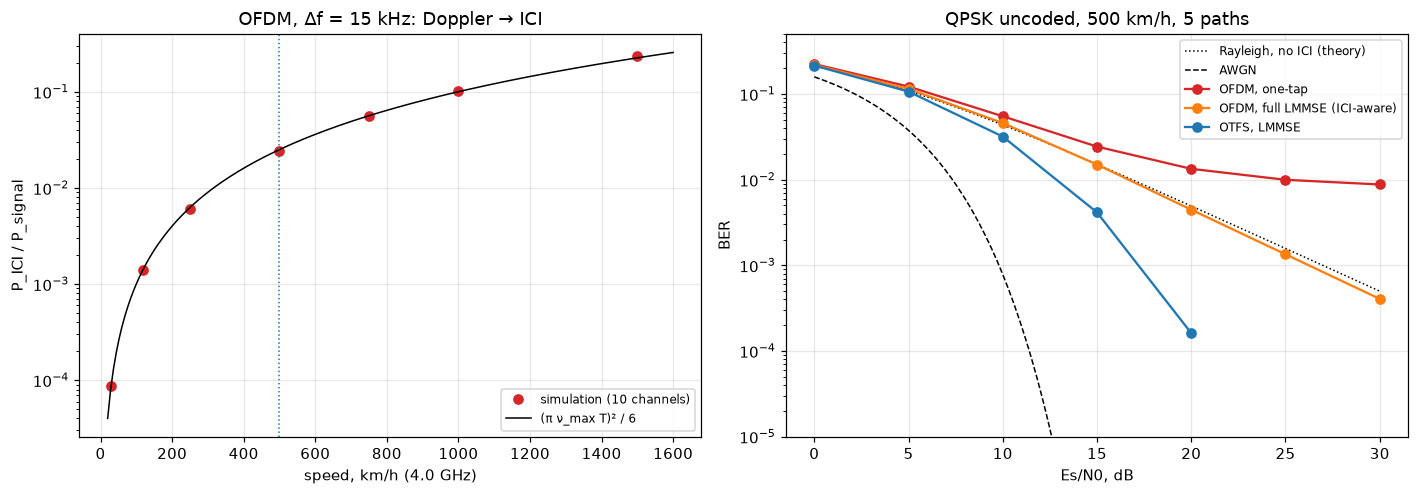

ofdm1 : BER at 20 dB = 1.3e-02, tail slope ≈ 0.1 decades per 10 dB (diversity order)
ofdm  : BER at 20 dB = 4.5e-03, tail slope ≈ 1.0 decades per 10 dB (diversity order)
otfs  : BER at 20 dB = 1.6e-04, tail slope ≈ 2.8 decades per 10 dB (diversity order)


In [6]:
# (a) ICI in OFDM: all the power off the diagonal of the channel matrix
speeds = np.array([30, 120, 250, 500, 750, 1000, 1500])
sir, sir_th = [], []
for v in speeds:
    nu_max = v / 3.6 * FC_GHZ * 1e9 / 3e8; tot = off = 0; th = []
    for i in range(10):
        r = np.random.default_rng(100 + i)
        p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
        nu = nu_max * np.cos(r.uniform(0, 2 * np.pi, P_PATHS))
        pth = [(np.sqrt(pi) * crandn((), r), l, vv) for l, (pi, vv) in enumerate(zip(p, nu))]
        Ho = eff_matrix(pth, ofdm_mod, ofdm_demod)
        d = np.abs(np.diag(Ho))**2; tot += d.sum(); off += (np.abs(Ho)**2).sum() - d.sum()
        th.append(np.sum(p * (1 - np.sinc(nu * T)**2)))
    sir.append(off / tot); sir_th.append(np.mean(th))
print("OFDM, ICI / useful power, dB: simulation (exact formula 1 − Σp_i·sinc²(ν_i T))")
print("   " + "  ".join(f"{v} km/h: {10*np.log10(a):.1f} ({10*np.log10(b):.1f})" for v, a, b in zip(speeds, sir, sir_th)))

# (b) BER: OFDM (one tap / full LMMSE) vs OTFS (LMMSE)
snrs = np.arange(0, 31, 5)
ber = {k: np.zeros(len(snrs)) for k in ("ofdm1", "ofdm", "otfs")}
t0 = time.time()
for f in range(FRAMES):
    pth = draw_paths(rng)
    Ht, Ho = eff_matrix(pth), eff_matrix(pth, ofdm_mod, ofdm_demod)
    b, x = qpsk_bits(4, rng)
    for i, snr in enumerate(snrs):
        n0 = 10 ** (-snr / 10)
        yo = (Ho @ x.T).T + np.sqrt(n0) * crandn(x.shape, rng)
        ber["ofdm1"][i] += np.mean(hard_bits(yo / np.diag(Ho)) != b)
        ber["ofdm"][i] += np.mean(hard_bits(lmmse(Ho, yo, n0)) != b)
        yt = (Ht @ x.T).T + np.sqrt(n0) * crandn(x.shape, rng)
        ber["otfs"][i] += np.mean(hard_bits(lmmse(Ht, yt, n0)) != b)
ber = {k: v / FRAMES for k, v in ber.items()}
print(f"{FRAMES} channel realizations in {time.time()-t0:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sv = np.linspace(20, 1600, 200); nuv = sv / 3.6 * FC_GHZ * 1e9 / 3e8
ax[0].semilogy(speeds, sir, "C3o", label="simulation (10 channels)")
ax[0].semilogy(sv, (np.pi * nuv * T)**2 / 6, "k-", lw=1, label="(π ν_max T)² / 6")
ax[0].axvline(SPEED_KMH, color="C0", ls=":", lw=1)
ax[0].set_xlabel(f"speed, km/h ({FC_GHZ} GHz)"); ax[0].set_ylabel("P_ICI / P_signal"); ax[0].legend(fontsize=8)
ax[0].set_title(f"OFDM, Δf = {DF/1e3:.0f} kHz: Doppler → ICI")
g = 10 ** (snrs / 10); sg = np.linspace(0, 30, 100); gg = 10 ** (sg / 10)
ax[1].semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Rayleigh, no ICI (theory)")
ax[1].semilogy(sg, 0.5 * erfc(np.sqrt(gg / 2)), "k--", lw=1, label="AWGN")
for k, c, lab in (("ofdm1", "C3", "OFDM, one-tap"), ("ofdm", "C1", "OFDM, full LMMSE (ICI-aware)"), ("otfs", "C0", "OTFS, LMMSE")):
    ok = ber[k] > 0
    ax[1].semilogy(snrs[ok], ber[k][ok], c + "o-", label=lab)
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlabel("Es/N0, dB"); ax[1].set_ylabel("BER"); ax[1].legend(fontsize=8)
ax[1].set_title(f"QPSK uncoded, {SPEED_KMH} km/h, {P_PATHS} paths")
plt.tight_layout(); plt.show()
for k in ber:
    j = np.nonzero(ber[k] > 0)[0][-2:]
    slope = -np.diff(np.log10(ber[k][j]))[0] / (np.diff(snrs[j])[0] / 10) if len(j) == 2 else np.nan
    print(f"{k:6}: BER at 20 dB = {ber[k][snrs == 20][0]:.1e}, tail slope ≈ {slope:.1f} decades per 10 dB (diversity order)")

## 5. Embedded pilot: estimating the channel directly in DD
In DD the channel is static, so one pilot per frame is enough (Raviteja et al., 2019). A pilot of energy $|x_p|^2$ sits at $(l_p,k_p)$, surrounded by a **guard band**: $\pm l_\max$ in delay and all $N$ bins in Doppler (fractional Doppler stretches the response along the whole axis). The guard takes 14 % of the frame, and its energy is given to the pilot (+21.6 dB). The receiver looks at the response inside the guard band, takes everything above $3\sigma$ as "virtual" paths with **integer** $(l,k)$, and builds $\hat H$ from them.

- **Integer Doppler**: the paths land exactly on cells, and the estimate is almost perfect. NMSE drops 10 dB for every 10 dB of SNR, and BER matches perfect CSI.
- **Fractional Doppler**: each path is a Dirichlet kernel. Its tails below the threshold are lost, and the "integer paths" model is inaccurate: the leakage from one position is not the same as from another (the phases $\phi_i(l,k)$ depend on $k$). NMSE stalls at −19 dB, and BER at a floor of ~$10^{-2}$.

Hence the interest in **Zak-OTFS**: there the pilot response predicts the response to any symbol exactly, fractional Doppler included.

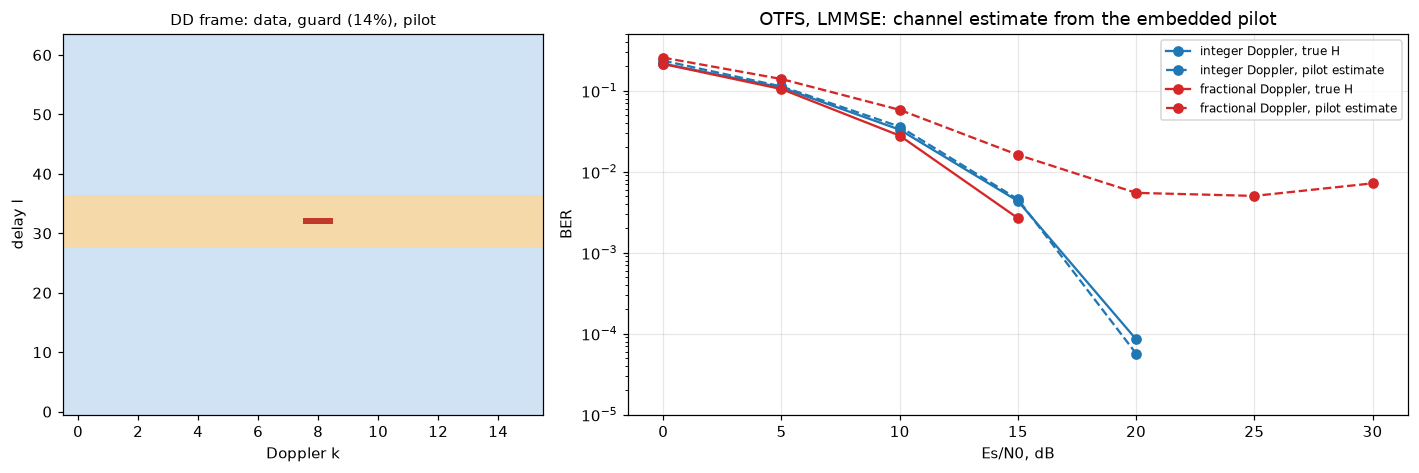

Pilot: 144·Es in one symbol (+21.6 dB), 14.4 taps found on average
  SNR  0 dB: NMSE H integer   -8.7 dB, fractional   -5.8 dB
  SNR  5 dB: NMSE H integer  -15.8 dB, fractional   -9.0 dB
  SNR 10 dB: NMSE H integer  -21.9 dB, fractional  -11.6 dB
  SNR 15 dB: NMSE H integer  -27.5 dB, fractional  -14.1 dB
  SNR 20 dB: NMSE H integer  -32.3 dB, fractional  -16.4 dB
  SNR 25 dB: NMSE H integer  -38.3 dB, fractional  -17.8 dB
  SNR 30 dB: NMSE H integer  -43.2 dB, fractional  -18.4 dB


In [7]:
# embedded pilot (Raviteja et al. 2019): pilot in the middle, a guard band in delay, across all Dopplers
LP, KP = M // 2, N // 2
GUARD = np.zeros((M, N), bool); GUARD[LP - (P_PATHS - 1):LP + P_PATHS] = True
DATA = ~GUARD.ravel()
XP = np.sqrt(GUARD.sum())                                 # pilot energy = energy of the displaced data

def unit_tap(l, k):
    """matrix of a single path with integer (l, k) and h = 1"""
    return eff_matrix([(1.0, l, k / (N * T))])

BASIS = {(l, k): unit_tap(l, k) for l in range(P_PATHS) for k in range(-N // 2, N // 2)}

def estimate(y, n0, thr=3.0):
    """DD response to the pilot → "virtual" integer taps above thr·σ → H_eff estimate"""
    Y = y.reshape(M, N); He = np.zeros((MN, MN), complex); taps = 0
    for (l, k), Hb in BASIS.items():
        pos = (LP + l) * N + (KP + k) % N
        v = Y.ravel()[pos] / (XP * Hb[pos, LP * N + KP])
        if abs(v) * XP > thr * np.sqrt(n0):
            He += v * Hb; taps += 1
    return He, taps

snrs5 = np.arange(0, 31, 5)
res5 = {k: np.zeros(len(snrs5)) for k in ("int_true", "int_est", "frac_true", "frac_est")}
nmse = {k: np.zeros(len(snrs5)) for k in ("int", "frac")}
ntaps = []
for f in range(FRAMES // 2):
    for integer, tag in ((True, "int"), (False, "frac")):
        pth = draw_paths(rng, integer); H = eff_matrix(pth)
        b, x = qpsk_bits(1, rng)
        x = x * DATA; x[0, LP * N + KP] = XP
        for i, snr in enumerate(snrs5):
            n0 = 10 ** (-snr / 10)
            y = (H @ x[0]) + np.sqrt(n0) * crandn(MN, rng)
            He, nt = estimate(y, n0); ntaps.append(nt)
            nmse[tag][i] += np.sum(np.abs(He - H)**2) / np.sum(np.abs(H)**2)
            for Hd, kk in ((H, "true"), (He, "est")):
                yd = y - Hd[:, LP * N + KP] * XP                  # cancel the pilot
                z = lmmse(Hd[:, DATA], yd[None], n0)[0]
                res5[f"{tag}_{kk}"][i] += np.mean(hard_bits(z) != b[0, DATA])
res5 = {k: v / (FRAMES // 2) for k, v in res5.items()}; nmse = {k: v / (FRAMES // 2) for k, v in nmse.items()}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [0.8, 1.3]})
G = np.zeros((M, N)); G[GUARD] = 1; G[LP, KP] = 2
ax[0].imshow(G, origin="lower", aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#cfe3f5", "#f5d9a8", "#c0392b"]),
             extent=[-0.5, N - 0.5, -0.5, M - 0.5])
ax[0].set_xlabel("Doppler k"); ax[0].set_ylabel("delay l"); ax[0].grid(False)
ax[0].set_title(f"DD frame: data, guard ({GUARD.mean():.0%}), pilot", fontsize=10)
for k, c, ls, lab in (("int_true", "C0", "-", "integer Doppler, true H"), ("int_est", "C0", "--", "integer Doppler, pilot estimate"),
                      ("frac_true", "C3", "-", "fractional Doppler, true H"), ("frac_est", "C3", "--", "fractional Doppler, pilot estimate")):
    ok = res5[k] > 0
    ax[1].semilogy(snrs5[ok], res5[k][ok], c + "o", ls=ls, label=lab)
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlabel("Es/N0, dB"); ax[1].set_ylabel("BER"); ax[1].legend(fontsize=8)
ax[1].set_title("OTFS, LMMSE: channel estimate from the embedded pilot")
plt.tight_layout(); plt.show()
print(f"Pilot: {XP**2:.0f}·Es in one symbol (+{10*np.log10(XP**2):.1f} dB), {np.mean(ntaps):.1f} taps found on average")
for i, snr in enumerate(snrs5):
    print(f"  SNR {snr:2d} dB: NMSE H integer {10*np.log10(nmse['int'][i]):6.1f} dB, fractional {10*np.log10(nmse['frac'][i]):6.1f} dB")

## 6. The detector: message passing instead of matrix inversion
LMMSE inverts an $MN\times MN$ matrix: $O((MN)^3)$, which is $10^9$ operations for a 64×16 frame and already $6\cdot10^{11}$ for a realistic 600×14 one. But with integer Doppler each row of $H$ has only $P$ nonzeros: the "observation ↔ symbol" graph is sparse, like an LDPC graph (`ldpc_sim`). **Message passing with a Gaussian approximation** (Raviteja et al., 2018):
1. observation $y_d$ sends symbol $c$ the mean and variance of the interference from the other $P-1$ symbols in its row, $\mu_{d,c}=\sum_{e\ne c}H_{d,e}\,\mathbb E[x_e]$, $\sigma^2_{d,c}=\sum_{e\ne c}|H_{d,e}|^2\mathrm{Var}[x_e]+N_0$;
2. a symbol collects from all of its observations **except** the recipient the likelihoods $\exp(-|y_d-\mu_{d,c}-H_{d,c}a|^2/\sigma^2_{d,c})$ for every constellation point $a$. This is the same extrinsic information as in BP and the turbo code;
3. damping $p\leftarrow0.6\,p_\text{new}+0.4\,p_\text{old}$ against oscillation on short cycles. The convergence indicator is the fraction of symbols with posterior probability > 0.99.

The cost is $O(MN\cdot P\cdot|\mathcal A|)$ per iteration. MP is also **better** than LMMSE: it is a nonlinear detector that exploits the finite symbol alphabet.

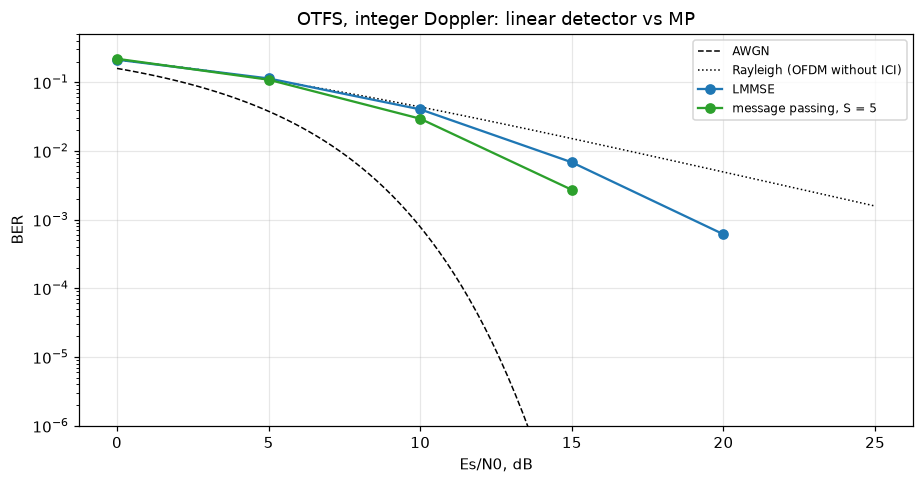

Time per frame: LMMSE 81 ms (O((MN)³) = 1.1e+09), MP 43 ms (O(MN·S·|A|·iterations) = 6.1e+05)
  SNR  0 dB: LMMSE 2.1e-01, MP 2.2e-01
  SNR  5 dB: LMMSE 1.1e-01, MP 1.1e-01
  SNR 10 dB: LMMSE 4.0e-02, MP 2.9e-02
  SNR 15 dB: LMMSE 6.8e-03, MP 2.7e-03
  SNR 20 dB: LMMSE 6.1e-04, MP 0.0e+00
  SNR 25 dB: LMMSE 0.0e+00, MP 0.0e+00


In [8]:
def mp_detect(y, H, n0, iters=30, damp=0.6, S=None):
    """Message passing with a Gaussian approximation of the interference (Raviteja et al. 2018).
    Observation y_d is linked only to the S strongest symbols of its row of H; the interference from the other S−1 is Gaussian.
    The convergence indicator η is the fraction of symbols with posterior probability > 0.99; the decision with the best η is kept."""
    S = S or int(np.max(np.sum(np.abs(H) > 1e-6 * np.abs(H).max(), 1)))
    idx = np.argsort(-np.abs(H), 1)[:, :S]; h = np.take_along_axis(H, idx, 1)
    A, A2 = QPSK, np.abs(QPSK)**2
    p = np.full((MN, S, 4), 0.25); best, eta_best = None, -1
    for _ in range(iters):
        m = p @ A; v = p @ A2 - np.abs(m)**2
        hm = h * m; hv = np.abs(h)**2 * v
        mu = hm.sum(1, keepdims=True) - hm; s2 = hv.sum(1, keepdims=True) - hv + n0
        ll = -np.abs(y[:, None, None] - mu[..., None] - h[..., None] * A)**2 / s2[..., None]
        LL = np.zeros((MN, 4)); np.add.at(LL, idx.ravel(), ll.reshape(-1, 4))
        post = np.exp(LL - LL.max(1, keepdims=True)); post /= post.sum(1, keepdims=True)
        eta = np.mean(post.max(1) > 0.99)
        if eta > eta_best:
            best, eta_best = A[np.argmax(LL, 1)], eta
        if eta == 1:
            break
        q = LL[idx] - ll; q = np.exp(q - q.max(-1, keepdims=True)); q /= q.sum(-1, keepdims=True)
        p = damp * q + (1 - damp) * p
    return best, S

snrs6 = np.arange(0, 26, 5)
r6 = {k: np.zeros(len(snrs6)) for k in ("lmmse", "mp")}; tl = tm = 0
for f in range(FRAMES // 2):
    pth = draw_paths(rng, integer=True); H = eff_matrix(pth)
    b, x = qpsk_bits(1, rng)
    for i, snr in enumerate(snrs6):
        n0 = 10 ** (-snr / 10); y = H @ x[0] + np.sqrt(n0) * crandn(MN, rng)
        t = time.time(); z = lmmse(H, y[None], n0)[0]; tl += time.time() - t
        t = time.time(); zm, S = mp_detect(y, H, n0); tm += time.time() - t
        r6["lmmse"][i] += np.mean(hard_bits(z) != b[0]); r6["mp"][i] += np.mean(hard_bits(zm) != b[0])
r6 = {k: v / (FRAMES // 2) for k, v in r6.items()}
fig, a = plt.subplots(figsize=(8.5, 4.5))
sg = np.linspace(0, 25, 100); gg = 10 ** (sg / 10)
a.semilogy(sg, 0.5 * erfc(np.sqrt(gg / 2)), "k--", lw=1, label="AWGN")
a.semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Rayleigh (OFDM without ICI)")
for k, c, lab in (("lmmse", "C0", "LMMSE"), ("mp", "C2", f"message passing, S = {S}")):
    ok = r6[k] > 0
    a.semilogy(snrs6[ok], r6[k][ok], c + "o-", label=lab)
a.set_ylim(1e-6, 0.5); a.set_xlabel("Es/N0, dB"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"OTFS, integer Doppler: linear detector vs MP")
plt.tight_layout(); plt.show()
print(f"Time per frame: LMMSE {tl/(len(snrs6)*FRAMES//2)*1e3:.0f} ms (O((MN)³) = {MN**3:.1e}), MP {tm/(len(snrs6)*FRAMES//2)*1e3:.0f} ms (O(MN·S·|A|·iterations) = {MN*S*4*30:.1e})")
for i, snr in enumerate(snrs6):
    print(f"  SNR {snr:2d} dB: LMMSE {r6['lmmse'][i]:.1e}, MP {r6['mp'][i]:.1e}")

## 7. Peak-to-average power
An OTFS sample is a sum of $N$ symbols (the IDFT over Doppler), an OFDM sample a sum of $M$. So without oversampling the OTFS frame PAPR is bounded by $10\log_{10}N$ dB (QPSK, all terms of unit magnitude), and the OFDM one by $10\log_{10}M$. For small $N$ OTFS is almost a single carrier. For $N\gtrsim16$ the sum is already Gaussian by the CLT, and the instantaneous-power distribution matches OFDM ($e^{-z}$). Oversampling (peaks between samples) adds ~1–3 dB at small $N$. The single-carrier DD variants (**OTSM/ODDM**, the last notebook in the series) exploit exactly this.

Frame PAPR (no oversampling); the bound is the number of symbols being added:
  OFDM:       max 11.3 dB, bound 10·lg M = 18.1 dB
  OTFS N =  1: max 0.0 dB, bound 10·lg N = 0.0 dB
  OTFS N =  2: max 3.0 dB, bound 10·lg N = 3.0 dB
  OTFS N =  4: max 6.0 dB, bound 10·lg N = 6.0 dB


  OTFS N = 16: max 10.5 dB, bound 10·lg N = 12.0 dB


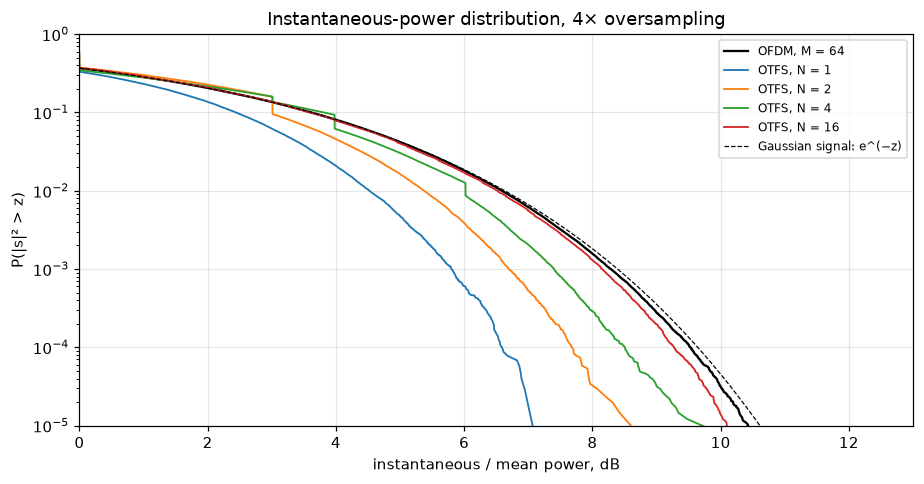

In [9]:
OS, B = 4, 400
def interp(blocks, L):
    """4× oversampling of a length-L block by zero-padding its spectrum (ideal low-pass)"""
    F = np.fft.fft(blocks, axis=-1); G = np.zeros(F.shape[:-1] + (L * OS,), complex)
    G[..., :L // 2] = F[..., :L // 2]; G[..., -L // 2:] = F[..., -L // 2:]
    return np.fft.ifft(G, axis=-1) * OS
z = np.linspace(0, 13, 300)
fig, a = plt.subplots(figsize=(8.5, 4.5))
_, X = qpsk_bits(B, rng)
so = interp((np.fft.ifft(X.reshape(B, M, N), axis=1) * np.sqrt(M)).swapaxes(1, 2), M)
pw = np.sort((np.abs(so)**2 / np.mean(np.abs(so)**2)).ravel())
a.semilogy(10 * np.log10(pw + 1e-12), 1 - np.arange(len(pw)) / len(pw), "k", lw=1.5, label=f"OFDM, M = {M}")
print("Frame PAPR (no oversampling); the bound is the number of symbols being added:")
print(f"  OFDM:       max {np.max(10*np.log10(np.max(np.abs(np.fft.ifft(X.reshape(B, M, N), axis=1) * np.sqrt(M))**2, axis=(1, 2)))):.1f} dB, bound 10·lg M = {10*np.log10(M):.1f} dB")
for i, n_ in enumerate((1, 2, 4, 16)):
    xs = qpsk_bits(B, rng)[1].reshape(B, M, N)[..., :n_]
    blocks = (np.fft.ifft(xs, axis=-1) * np.sqrt(n_)).swapaxes(1, 2)        # (B, n_, M): N blocks of M samples
    st = interp(blocks.reshape(B, -1), M * n_)
    pw = np.sort((np.abs(st)**2 / np.mean(np.abs(st)**2)).ravel())
    a.semilogy(10 * np.log10(pw + 1e-12), 1 - np.arange(len(pw)) / len(pw), f"C{i}", lw=1.2, label=f"OTFS, N = {n_}")
    print(f"  OTFS N = {n_:2d}: max {10*np.log10(np.max(np.abs(blocks)**2)):.1f} dB, bound 10·lg N = {10*np.log10(n_):.1f} dB")
a.semilogy(z, np.exp(-10 ** (z / 10)), "k--", lw=0.8, label="Gaussian signal: e^(−z)")
a.set_ylim(1e-5, 1); a.set_xlim(0, 13); a.set_xlabel("instantaneous / mean power, dB"); a.set_ylabel("P(|s|² > z)")
a.legend(fontsize=8); a.set_title("Instantaneous-power distribution, 4× oversampling")
plt.tight_layout(); plt.show()

## Comparison with OFDM (LTE)
| | OFDM / LTE | OTFS |
|---|---|---|
| Where symbols live | TF grid: subcarrier × symbol | DD grid: delay × Doppler |
| Channel a symbol sees | one complex number $H[m,n]$, varying across the grid | a 2-D convolution with a few fixed paths |
| Doppler | ICI $\approx(\pi\nu_\max T)^2/6$; pilots must keep up with the channel | just a shift along the Doppler axis while $\nu_\max<N/(2\cdot NT)$ |
| Uncoded diversity | 1 (Rayleigh on every RE) | effectively ~$P$ (each symbol spans the whole frame) |
| Channel estimation | CRS/DMRS across the grid + interpolation | one pilot + guard (14 % here); a floor under fractional Doppler |
| Equalizer | one division per subcarrier | LMMSE $O((MN)^3)$ or MP $O(MN\,P\,|\mathcal A|)$ |
| CP | per symbol (11 % here) | one per frame (0.8 %) |
| Latency | a 67 µs symbol | the whole $NT$ frame (~1 ms here) |
| PAPR | Gaussian, $\sim10\log_{10}M$ bound | $\le10\log_{10}N$: lower for small $N$ |
| Compatibility | the 4G/5G standard | an ISFFT precoder **on top of** an OFDM modem |

OTFS does not replace OFDM: it is a 2-D precoder (the ISFFT) in front of the same modem. It wins when the channel changes quickly in time (trains, aircraft, LEO satellites, V2X) and a code with interleaving cannot collect the diversity within the latency budget. When Doppler is small (`SPEED_KMH = 30`), OFDM with a good code is just as good and much simpler. The price of OTFS is a complex detector and sensitivity to fractional Doppler (section 5). That price is lowered by Zak-OTFS (an exact channel model), AFDM/OCDM (a chirp basis, another parametrization of delay–Doppler) and OTSM/ODDM (a single carrier).

## Things to try
- `SPEED_KMH = 30` — in section 4 the OFDM ICI drops to −40 dB, one-tap OFDM matches full LMMSE and the Rayleigh curve, yet OTFS is still steeper: the delay diversity has not gone anywhere
- `SPEED_KMH = 1500` — OFDM ICI is −6 dB, while OTFS barely notices: $k_\max\approx6$ bins is still below $N/2$
- `N = 32` (a frame twice as long) — the Doppler bin is half as wide: in section 3 more paths are resolved separately, and in section 5 fractional Doppler hurts less (finer resolution)
- `P_PATHS = 2` — in section 4 the OTFS slope drops to about 2: diversity is the number of resolvable paths
- `L_CP = 2` with `P_PATHS = 5` — a CP shorter than the channel: OTFS gets inter-frame interference, OFDM inter-symbol interference (compare the floors)
- in section 6 `damp=1.0` (no damping) — MP may start oscillating on some frames, and then an error floor appears